# P5 · Análisis estadístico y visualizaciones en Python: Dónde, cuándo y a quién vender

**Objetivo:** Analizar el comportamiento de las ventas del supermercado con el CSV limpio para respaldar decisiones comerciales a partir de las tres preguntas clave del proyecto.

**Preguntas del proyecto:**
1. **Dónde:** ¿En qué sucursales y líneas de producto se concentran los ingresos?
2. **Cuándo:** ¿En qué horas, días de la semana y meses se generan más ingresos?
3. **Quién:** ¿Cómo se comportan el ticket promedio y la satisfacción según el tipo de cliente y el género?

## Carga de datos
El archivo `supermercado.csv` es el CSV limpio generado en **P2** a partir del dataset público **Supermarket Sales** (`1,000` transacciones, enero–marzo de 2019). Como se sube al almacenamiento temporal de la sesión de Colab, al abrir el enlace público se verán las salidas guardadas; si deseas reejecutarlo desde cero, sube `supermercado.csv` (o incluye aquí los pasos de limpieza de P2).

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")

df = pd.read_csv("supermercado.csv")

orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["dia_semana"] = pd.Categorical(df["dia_semana"], categories=orden_dias, ordered=True)
df["mes"] = pd.Categorical(df["mes"], categories=[1, 2, 3], ordered=True)

print("Filas y columnas:", df.shape)
print("Columnas:", df.columns.tolist())

Filas y columnas: (1000, 20)
Columnas: ['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5pct', 'total', 'date', 'time', 'payment', 'cost_of_goods_sold', 'gross_margin_percentage', 'gross_income', 'customer_satisfaction_rating', 'dia_semana', 'hora', 'mes']


## 1. Descripción de los datos
¿Cómo se distribuye el ingreso por venta (`total`, con impuesto del 5% incluido) y qué muestran su media, mediana y dispersión general?

count    1000.000000
mean      322.966749
std       245.885335
min        10.678500
25%       124.422375
50%       253.848000
75%       471.350250
max      1042.650000
Name: total, dtype: float64
Media: 322.97 | Mediana: 253.85


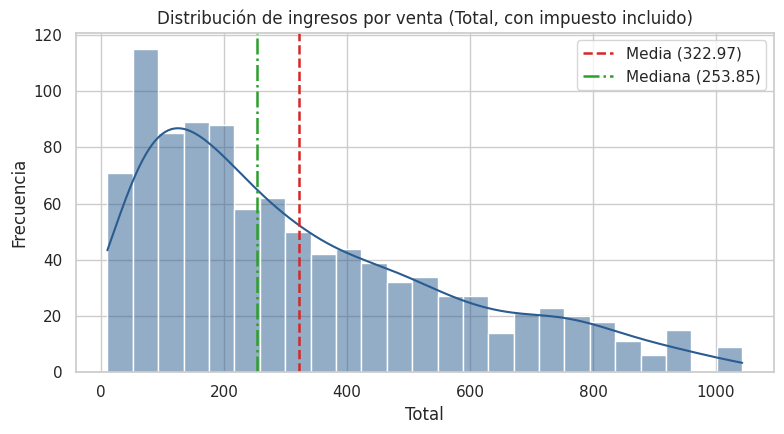

In [11]:
desc_total = df["total"].describe()
media_total = df["total"].mean()
mediana_total = df["total"].median()

print(desc_total)
print(f"Media: {media_total:,.2f} | Mediana: {mediana_total:,.2f}")

plt.figure(figsize=(8, 4.5))
sns.histplot(df["total"], bins=25, kde=True, color="#2b5c8f")
plt.axvline(media_total, color="#d62728", linestyle="--", linewidth=1.8, label=f"Media ({media_total:,.2f})")
plt.axvline(mediana_total, color="#2ca02c", linestyle="-.", linewidth=1.8, label=f"Mediana ({mediana_total:,.2f})")
plt.title("Distribución de ingresos por venta (Total, con impuesto incluido)")
plt.xlabel("Total")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

## 2. Dónde: ingresos por sucursal y línea de producto
¿Qué sucursales y líneas de producto aportan más ingresos? Se muestran las etiquetas con sucursal y ciudad (`A (Yangon)`, `B (Mandalay)`, `C (Naypyitaw)`).

branch                  A (Yangon)  B (Mandalay)  C (Naypyitaw)
product_line                                                   
Electronic Accessories    18317.11      17051.44       18968.97
Fashion Accessories       16332.51      16413.32       21560.07
Food And Beverages        17163.10      15214.89       23766.86
Health And Beauty         12597.75      19980.66       16615.33
Home And Lifestyle        22417.20      17549.16       13895.55
Sports And Travel         19372.70      19988.20       15761.93
Ingresos por sucursal: {'A (Yangon)': 106200.37, 'B (Mandalay)': 106197.67, 'C (Naypyitaw)': 110568.71}
Suma total: 322966.75


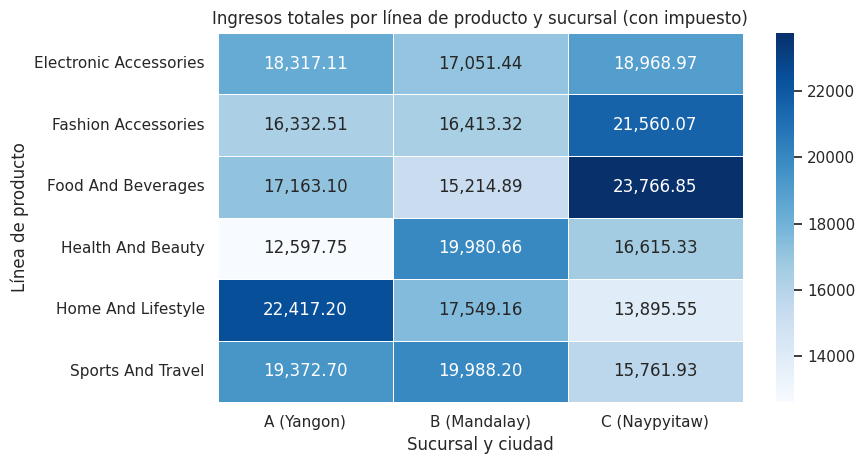

In [12]:
etiquetas_sucursal = {
    "A": "A (Yangon)",
    "B": "B (Mandalay)",
    "C": "C (Naypyitaw)"
}

pivote_donde = df.pivot_table(
    index="product_line",
    columns="branch",
    values="total",
    aggfunc="sum",
    fill_value=0
).rename(columns=etiquetas_sucursal)

print(pivote_donde.round(2))
print("Ingresos por sucursal:", pivote_donde.sum().round(2).to_dict())
print("Suma total:", round(pivote_donde.values.sum(), 2))

plt.figure(figsize=(9, 4.8))
sns.heatmap(pivote_donde, annot=True, fmt=",.2f", cmap="Blues", linewidths=0.5)
plt.title("Ingresos totales por línea de producto y sucursal (con impuesto)")
plt.xlabel("Sucursal y ciudad")
plt.ylabel("Línea de producto")
plt.tight_layout()
plt.show()

## 3. Cuándo: ingresos por hora, día de la semana y mes
¿En qué horas (10 a 20), días de la semana (lunes a domingo) y meses (1 a 3) se concentran los ingresos?

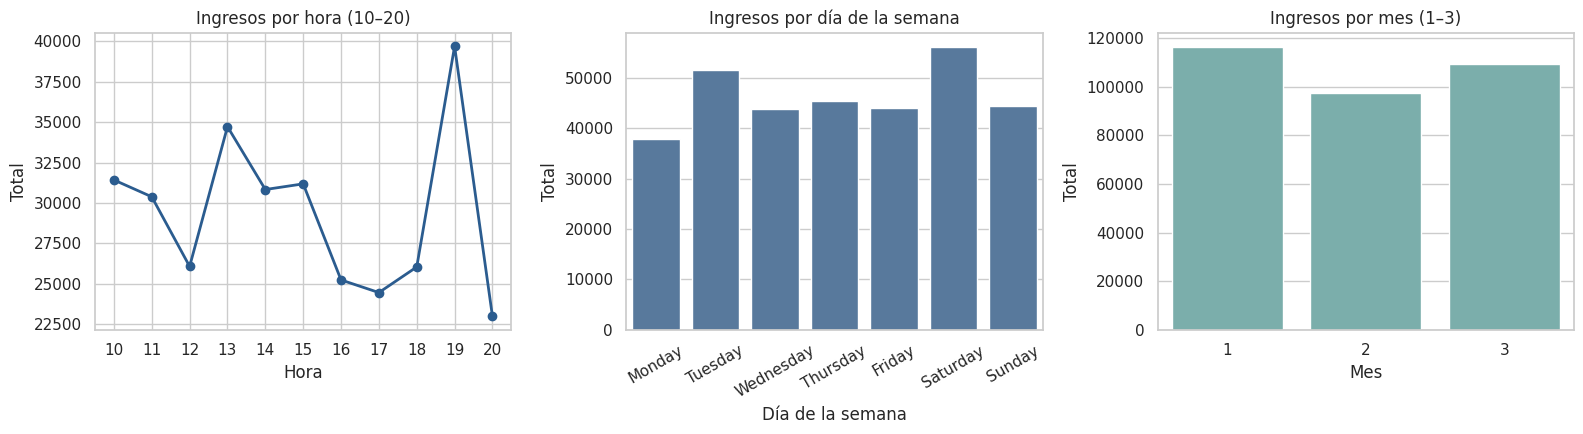

In [13]:
ing_hora = df.groupby("hora", observed=False)["total"].sum().reindex(range(10, 21), fill_value=0)
ing_dia = df.groupby("dia_semana", observed=False)["total"].sum()
ing_mes = df.groupby("mes", observed=False)["total"].sum()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(ing_hora.index, ing_hora.values, marker="o", color="#2b5c8f", linewidth=2)
axes[0].set_title("Ingresos por hora (10–20)")
axes[0].set_xlabel("Hora")
axes[0].set_ylabel("Total")
axes[0].set_xticks(range(10, 21))

sns.barplot(x=ing_dia.index, y=ing_dia.values, ax=axes[1], color="#4c78a8")
axes[1].set_title("Ingresos por día de la semana")
axes[1].set_xlabel("Día de la semana")
axes[1].set_ylabel("Total")
axes[1].tick_params(axis="x", rotation=30)

sns.barplot(x=ing_mes.index.astype(str), y=ing_mes.values, ax=axes[2], color="#72b7b2")
axes[2].set_title("Ingresos por mes (1–3)")
axes[2].set_xlabel("Mes")
axes[2].set_ylabel("Total")

plt.tight_layout()
plt.show()

## 4. Quién: ticket promedio y satisfacción por tipo de cliente y género
¿Cómo se comparan el ticket promedio (`mean` de `total`) y la satisfacción promedio (`mean` de `customer_satisfaction_rating`) entre `Member` y `Normal`, y entre `Female` y `Male`?

               ticket_promedio  satisfaccion_promedio  ventas
customer_type                                                
Member                  327.79                   6.94     501
Normal                  318.12                   7.01     499
Diferencia porcentual ticket (Member vs Normal): +3.04%

        ticket_promedio  satisfaccion_promedio  ventas
gender                                                
Female           335.10                   6.96     501
Male             310.79                   6.98     499
Diferencia porcentual ticket (Female vs Male): +7.82%


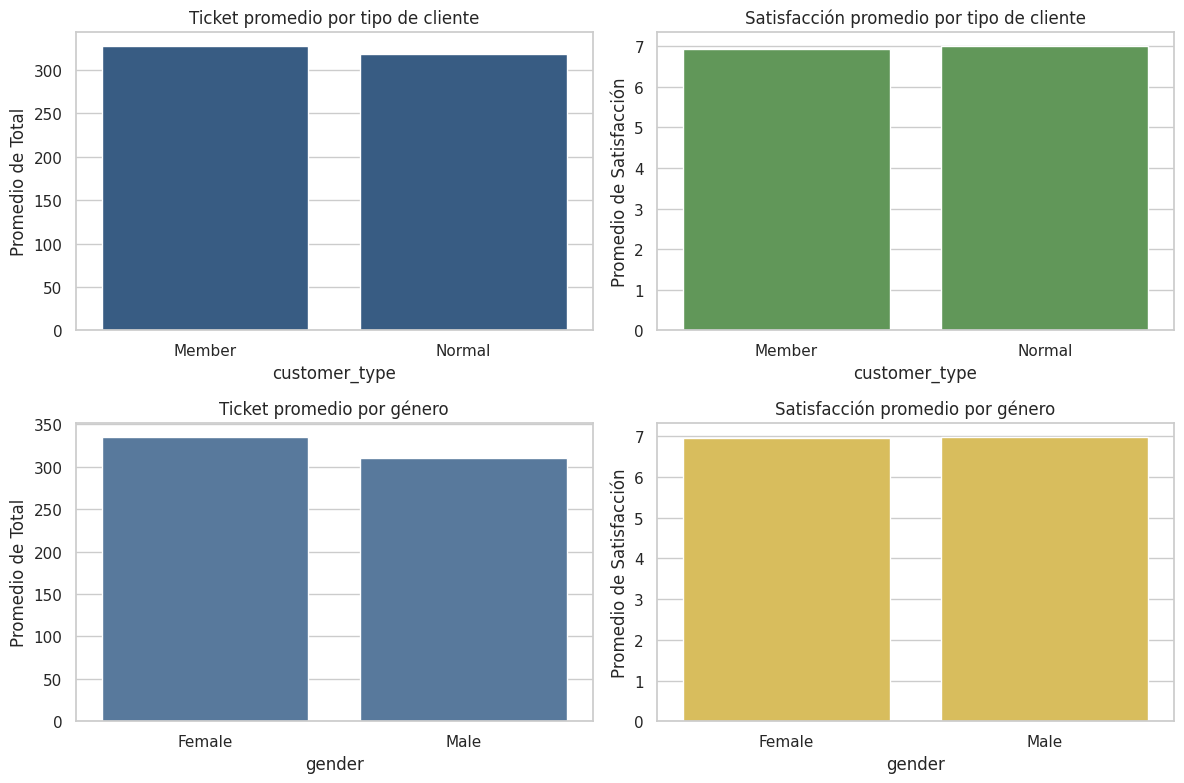

In [14]:
resumen_cliente = df.groupby("customer_type", observed=False).agg(
    ticket_promedio=("total", "mean"),
    satisfaccion_promedio=("customer_satisfaction_rating", "mean"),
    ventas=("invoice_id", "count")
)

resumen_genero = df.groupby("gender", observed=False).agg(
    ticket_promedio=("total", "mean"),
    satisfaccion_promedio=("customer_satisfaction_rating", "mean"),
    ventas=("invoice_id", "count")
)

t_member = resumen_cliente.loc["Member", "ticket_promedio"]
t_normal = resumen_cliente.loc["Normal", "ticket_promedio"]
dif_pct_cliente = ((t_member - t_normal) / t_normal) * 100

t_female = resumen_genero.loc["Female", "ticket_promedio"]
t_male = resumen_genero.loc["Male", "ticket_promedio"]
dif_pct_genero = ((t_female - t_male) / t_male) * 100

print(resumen_cliente.round(2))
print(f"Diferencia porcentual ticket (Member vs Normal): {dif_pct_cliente:+.2f}%")
print()
print(resumen_genero.round(2))
print(f"Diferencia porcentual ticket (Female vs Male): {dif_pct_genero:+.2f}%")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.barplot(data=df, x="customer_type", y="total", estimator="mean", errorbar=None, ax=axes[0, 0], color="#2b5c8f")
axes[0, 0].set_title("Ticket promedio por tipo de cliente")
axes[0, 0].set_ylabel("Promedio de Total")

sns.barplot(data=df, x="customer_type", y="customer_satisfaction_rating", estimator="mean", errorbar=None, ax=axes[0, 1], color="#59a14f")
axes[0, 1].set_title("Satisfacción promedio por tipo de cliente")
axes[0, 1].set_ylabel("Promedio de Satisfacción")

sns.barplot(data=df, x="gender", y="total", estimator="mean", errorbar=None, ax=axes[1, 0], color="#4c78a8")
axes[1, 0].set_title("Ticket promedio por género")
axes[1, 0].set_ylabel("Promedio de Total")

sns.barplot(data=df, x="gender", y="customer_satisfaction_rating", estimator="mean", errorbar=None, ax=axes[1, 1], color="#edc948")
axes[1, 1].set_title("Satisfacción promedio por género")
axes[1, 1].set_ylabel("Promedio de Satisfacción")

plt.tight_layout()
plt.show()

## 5. Estadística: correlación, valores atípicos (IQR) y pruebas t
¿Qué correlación existe entre `quantity` y `total`, qué valores atípicos aparecen con IQR y qué arrojan las pruebas *t* de Welch para tipo de cliente (`Member` vs. `Normal`) y género (`Female` vs. `Male`)?

In [15]:
corr_pearson = df["quantity"].corr(df["total"])
corr_spearman = df["quantity"].corr(df["total"], method="spearman")

q1 = df["total"].quantile(0.25)
q3 = df["total"].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
outliers = df[(df["total"] < lim_inf) | (df["total"] > lim_sup)]

# Prueba t de Welch para tipo de cliente (Member vs Normal)
g_member = df.loc[df["customer_type"] == "Member", "total"]
g_normal = df.loc[df["customer_type"] == "Normal", "total"]
t_cli, p_cli = stats.ttest_ind(g_member, g_normal, equal_var=False)

diff_cli = g_member.mean() - g_normal.mean()
se_cli = np.sqrt(g_member.var(ddof=1) / len(g_member) + g_normal.var(ddof=1) / len(g_normal))
df_cli = (se_cli**4) / (
    ((g_member.var(ddof=1) / len(g_member))**2) / (len(g_member) - 1) +
    ((g_normal.var(ddof=1) / len(g_normal))**2) / (len(g_normal) - 1)
)
ci_cli_low, ci_cli_high = stats.t.interval(0.95, df=df_cli, loc=diff_cli, scale=se_cli)

# Prueba t de Welch para género (Female vs Male)
g_female = df.loc[df["gender"] == "Female", "total"]
g_male = df.loc[df["gender"] == "Male", "total"]
t_gen, p_gen = stats.ttest_ind(g_female, g_male, equal_var=False)

diff_gen = g_female.mean() - g_male.mean()
se_gen = np.sqrt(g_female.var(ddof=1) / len(g_female) + g_male.var(ddof=1) / len(g_male))
df_gen = (se_gen**4) / (
    ((g_female.var(ddof=1) / len(g_female))**2) / (len(g_female) - 1) +
    ((g_male.var(ddof=1) / len(g_male))**2) / (len(g_male) - 1)
)
ci_gen_low, ci_gen_high = stats.t.interval(0.95, df=df_gen, loc=diff_gen, scale=se_gen)

print(f"Correlación Pearson (quantity vs total): {corr_pearson:.2f} | Spearman: {corr_spearman:.2f}")
print(f"Q1: {q1:.2f}, Q3: {q3:.2f}, IQR: {iqr:.2f} | Límites: [{lim_inf:.2f}, {lim_sup:.2f}]")
print(f"Outliers detectados: {len(outliers)} | Máximo de total: {df['total'].max():.2f}")
# Los 9 valores extremos superiores son ventas altas legítimas que no se eliminaron.
print(f"Prueba t Cliente (Member vs Normal): t = {t_cli:.3f}, p = {p_cli:.3f}, IC 95% = [{ci_cli_low:.2f}, {ci_cli_high:.2f}]")
print(f"Prueba t Género (Female vs Male): t = {t_gen:.2f}, p = {p_gen:.3f}, IC 95% = [{ci_gen_low:.2f}, {ci_gen_high:.2f}]")

Correlación Pearson (quantity vs total): 0.71 | Spearman: 0.74
Q1: 124.42, Q3: 471.35, IQR: 346.93 | Límites: [-395.97, 991.74]
Outliers detectados: 9 | Máximo de total: 1042.65
Prueba t Cliente (Member vs Normal): t = 0.622, p = 0.534, IC 95% = [-20.86, 40.19]
Prueba t Género (Female vs Male): t = 1.56, p = 0.118, IC 95% = [-6.19, 54.80]


## 6. Verificación cruzada
¿Coinciden los totales calculados en Python con los resultados de SQL y Tableau?

In [16]:
total_general = df["total"].sum()
total_sabado = df.loc[df["dia_semana"] == "Saturday", "total"].sum()
total_hora_19 = df.loc[df["hora"] == 19, "total"].sum()
n_ventas = len(df)
ticket_prom = df["total"].mean()

verificacion = pd.DataFrame({
    "Métrica": ["Ingresos totales", "Sábado (Saturday)", "Hora 19", "Número de ventas", "Ticket promedio"],
    "Python (CSV limpio)": [
        round(total_general, 2),
        round(total_sabado, 2),
        round(total_hora_19, 2),
        n_ventas,
        round(ticket_prom, 2)
    ],
    "Referencia SQL / Tableau": [322966.75, 56120.81, 39699.51, 1000, 322.97]
})
verificacion["Diferencia"] = (verificacion["Python (CSV limpio)"] - verificacion["Referencia SQL / Tableau"]).round(2)

print(verificacion.to_string(index=False))

          Métrica  Python (CSV limpio)  Referencia SQL / Tableau  Diferencia
 Ingresos totales            322966.75                 322966.75         0.0
Sábado (Saturday)             56120.81                  56120.81         0.0
          Hora 19             39699.51                  39699.51         0.0
 Número de ventas              1000.00                   1000.00         0.0
  Ticket promedio               322.97                    322.97         0.0


## Conclusiones
- **Dónde:** **Naypyitaw (C)** es la sucursal con más ingresos (**110,568.71**). La línea líder por sucursal es **Food And Beverages** en **C** (**23,766.86**), **Home And Lifestyle** en **A** (**22,417.20**) y **Sports And Travel** en **B** (**19,988.20**).
- **Cuándo:** **Enero** fue el mes más fuerte (**116,291.87**) y **febrero** el más bajo (**97,219.37**); por día destaca el **sábado** (**56,120.81**) y por horario sobresale la **hora 19** (**39,699.51**).
- **Quién:** **Member** gasta **3.04%** más que **Normal** (IC [−20.86, 40.19], p = 0.534) y **Female** **7.82%** más que **Male** (IC [−6.19, 54.80], p = 0.118). En ambos casos el intervalo incluye el cero, así que no hay evidencia suficiente de una diferencia real, y la satisfacción es prácticamente igual (6.94 a 7.01).
- **Estadística:** **cantidad** y **total** tienen correlación positiva fuerte (**Pearson 0.71**, **Spearman 0.74**), y los **9 valores extremos superiores** son ventas altas legítimas que no se eliminaron.

## Limitaciones
- El dataset contiene **1,000 ventas** registradas durante **3 meses** (enero–marzo de 2019).
- El **margen bruto es constante** y corresponde a **datos de un solo supermercado** (con el 5% de impuesto ya incluido en `total`).